# Tuned In: Formative User Feedback analysis

This notebook combines a ZIP file containing participant export folders. It is designed for descriptive formative analysis: finding usability and adaptive-rule patterns that can guide the next version.

## Before you run it

1. Put all participant export folders into one ZIP file.
2. Update `EXPORT_ZIP` below.
3. Run the cells from top to bottom.

The notebook ignores macOS `__MACOSX` files automatically.

In [37]:
# Run once if your notebook environment does not already have these packages.
# %pip install pandas matplotlib

from io import BytesIO
from pathlib import Path
import json
import zipfile

import matplotlib.pyplot as plt
import pandas as pd

pd.set_option('display.max_columns', None)
pd.set_option('display.float_format', lambda value: f'{value:,.3f}')


In [38]:
# Change this path to your combined results ZIP file.
EXPORT_ZIP = Path(r'/Users/zi/Documents/GitHub/TunedIn-Web/feedback-files/results/iterative-1.zip')
assert EXPORT_ZIP.exists(), f'File not found: {EXPORT_ZIP}'


In [39]:
def load_exports(zip_path):
    """Load every blocks.csv, decisions.csv, and session.json in an export ZIP."""
    tables = {'blocks': [], 'decisions': [], 'sessions': []}
    with zipfile.ZipFile(zip_path) as archive:
        names = [name for name in archive.namelist() if '__MACOSX' not in name]
        for name in names:
            if name.endswith('/blocks.csv'):
                tables['blocks'].append(pd.read_csv(BytesIO(archive.read(name))))
            elif name.endswith('/decisions.csv'):
                tables['decisions'].append(pd.read_csv(BytesIO(archive.read(name))))
            elif name.endswith('/session.json'):
                tables['sessions'].append(json.loads(archive.read(name)))
    blocks = pd.concat(tables['blocks'], ignore_index=True)
    decisions = pd.concat(tables['decisions'], ignore_index=True)
    sessions = pd.DataFrame(tables['sessions'])
    return blocks, decisions, sessions

blocks, decisions, sessions = load_exports(EXPORT_ZIP)
print(f'Participants: {sessions.participantId.nunique()}')
print(f'Block rows: {len(blocks)} | Adaptive decisions: {len(decisions)}')


Participants: 3
Block rows: 9 | Adaptive decisions: 32


In [40]:
# Keep only completed task attempts. Empty interrupted-restart rows are retained
# in the source CSV but excluded from performance summaries.
if 'attempt_status' in blocks.columns:
    completed_blocks = blocks.loc[blocks['attempt_status'].eq('completed')].copy()
else:
    completed_blocks = blocks.copy()

numeric_block_columns = [
    'duration_seconds', 'records_presented', 'validated_records',
    'validated_records_per_minute', 'median_il_ms', 'median_fped_ms',
    'first_pass_error_rate'
]
for column in numeric_block_columns:
    if column in completed_blocks:
        completed_blocks[column] = pd.to_numeric(completed_blocks[column], errors='coerce')

adaptive_blocks = (
    completed_blocks
    .query("condition == 'Adaptive music'")
    .copy()
    .reset_index(drop=True)
)
adaptive_blocks[['participant_id', 'duration_seconds', 'validated_records',
                 'validated_records_per_minute', 'median_il_ms', 'median_fped_ms',
                 'first_pass_error_rate']]


,participant_id,duration_seconds,validated_records,validated_records_per_minute,median_il_ms,median_fped_ms,first_pass_error_rate
0,P003,360,21,3.500,"1,848.600","12,366.300",0.238
1,P001,360,29,4.833,"1,310.000","9,619.000",0.103
2,P002,360,27,4.500,"1,463.700","10,344.500",0.074


## Decision eligibility

The Adaptive Music rule engine evaluates recent performance using a rolling time window. An evaluation can only apply the Reduced, Baseline, or Elevated rules when enough records are available within that window.

`MINIMUM_RECORD_COUNT` is the minimum number of recent records required before the engine can make a performance-based decision. It is not a maximum.

For example, with `MINIMUM_RECORD_COUNT = 5`:

- Fewer than five recent records: the evaluation is not eligible, so the engine keeps its current playback state.
- Five or more recent records: the evaluation is eligible, so the engine compares recent performance with the participant’s Silent Baseline Calibration.

The analysis creates these additional values:

| Column | Meaning |
| --- | --- |
| `eligible` | `True` when the recent window contains at least the required number of records; otherwise `False`. |
| `il_ratio` | Recent median initiation latency divided by baseline median initiation latency. Values below `1.00` mean the participant initiated typing faster than baseline; values above `1.00` mean they were slower. |
| `fped_ratio` | Recent median first-pass entry duration divided by baseline median first-pass entry duration. Values below `1.00` mean faster entry than baseline; values above `1.00` mean slower entry. |
| `evaluations` | Total number of Adaptive Music rule-engine checks for the participant. |
| `eligible_evaluations` | Number of checks with enough recent records to apply the performance rules. |
| `mean_records_in_window` | Average number of records available in the rolling window across checks. |
| `eligible_percent` | Percentage of checks that were eligible for a performance-based decision. |

This summary helps identify whether the rule engine is unable to reach a state because the thresholds are too strict, or because too few records are available in the rolling window.

In [41]:
# Decision eligibility: an evaluation can only apply the rule once it has
# enough records in its rolling window. Change this value to inspect options.
MINIMUM_RECORD_COUNT = 5

decision_numbers = [
    'record_count', 'median_il_ms', 'median_fped_ms', 'first_pass_error_rate',
    'baseline_il_ms', 'baseline_fped_ms'
]
for column in decision_numbers:
    decisions[column] = pd.to_numeric(decisions[column], errors='coerce')

decisions['eligible'] = decisions['record_count'] >= MINIMUM_RECORD_COUNT
decisions['il_ratio'] = decisions['median_il_ms'] / decisions['baseline_il_ms']
decisions['fped_ratio'] = decisions['median_fped_ms'] / decisions['baseline_fped_ms']

eligibility = (decisions.groupby('participant_id', as_index=False)
    .agg(evaluations=('eligible', 'size'),
         eligible_evaluations=('eligible', 'sum'),
         mean_records_in_window=('record_count', 'mean'))
)
eligibility['eligible_percent'] = 100 * eligibility['eligible_evaluations'] / eligibility['evaluations']
eligibility


,participant_id,evaluations,eligible_evaluations,mean_records_in_window,eligible_percent
0,P001,11,8,4.909,72.727
1,P002,10,4,4.400,40.000
2,P003,11,0,3.545,0.000


## Playback-state selections and decision reasons

The Adaptive Music engine records a selected playback state at each evaluation. The possible states are:

- `baseline`
- `reduced`
- `elevated`

The `state_counts` table summarizes how often each state was selected for each participant.

These counts should be interpreted carefully. A selected state may be retained from an earlier evaluation while the engine waits for enough recent records. Therefore, a count of several `reduced` selections does not necessarily mean that the music changed to Reduced several times.

The `reason_counts` table explains why each state was selected. Common reasons include:

| Reason | Meaning |
| --- | --- |
| `Kept the previous state while waiting for enough recent records.` | The rolling window did not contain the minimum required number of records, so the engine could not apply the performance rules. |
| `Neither reduced nor elevated trigger conditions were met.` | Enough records were available, but recent performance did not meet the Reduced or Elevated conditions. |
| `Recent performance met a reduced-state trigger.` | Enough records were available, and recent speed or error performance met at least one Reduced condition. |
| `Recent performance met every elevated-state trigger.` | Enough records were available, and recent speed and error performance met all Elevated conditions. |

Together, these tables distinguish between two different reasons why a state may be absent:

1. The engine did not have enough records to evaluate the rule.
2. The engine evaluated the rule, but the participant’s performance did not meet the state’s trigger conditions.

In [42]:
# Selected states include retained states while the next evaluation is waiting
# for enough records. The reason column distinguishes real triggers from retention.
state_counts = (decisions.pivot_table(index='participant_id', columns='selected_state',
                                      values='block', aggfunc='size', fill_value=0)
                  .reset_index())
state_counts

reason_counts = (decisions.groupby(['participant_id', 'reason'], as_index=False)
                 .size().sort_values(['participant_id', 'size'], ascending=[True, False]))
reason_counts


,participant_id,reason,size
1,P001,Neither reduced nor elevated trigger condition...,6
0,P001,Kept the previous state while waiting for enou...,3
2,P001,Recent performance met a reduced-state trigger.,2
3,P002,Kept the previous state while waiting for enou...,6
4,P002,Neither reduced nor elevated trigger condition...,3
5,P002,Recent performance met a reduced-state trigger.,1
6,P003,Kept the previous state while waiting for enou...,11


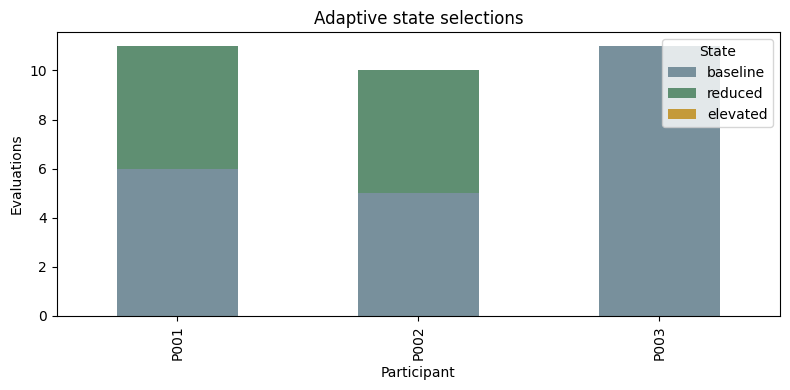

In [43]:
# Visual summary of the current state selections.
plot_data = (decisions.groupby(['participant_id', 'selected_state']).size()
             .unstack(fill_value=0).reindex(columns=['baseline', 'reduced', 'elevated'], fill_value=0))
ax = plot_data.plot(kind='bar', stacked=True, figsize=(8, 4),
                    color={'baseline': '#78909c', 'reduced': '#5f8f72', 'elevated': '#c49a3a'})
ax.set(title='Adaptive state selections', xlabel='Participant', ylabel='Evaluations')
ax.legend(title='State')
plt.tight_layout()


## Offline simulation of Elevated-rule settings

This section tests alternative Elevated playback-state settings using decisions that have already been recorded. It does not change the application, participant data, or saved exports.

Each candidate rule has three settings:

| Setting | Meaning |
| --- | --- |
| `minimum_records` | Minimum number of records required in the rolling window before the engine can evaluate performance. |
| `speed_cutoff` | Maximum proportion of the participant’s baseline median IL and FPED required for Elevated. |
| `max_error_rate` | Maximum first-pass record error rate permitted for Elevated. |

The simulation first keeps only evaluations with enough records under the candidate `minimum_records` setting.

It then marks an evaluation as `would_select_elevated` only when all of the following are true:

1. Recent median initiation latency is at or below the selected `speed_cutoff` relative to baseline.
2. Recent median first-pass entry duration is at or below the selected `speed_cutoff` relative to baseline.
3. Recent first-pass record error rate is at or below `max_error_rate`.

A higher `speed_cutoff` is easier to reach because the rule compares recent performance using:

```text
recent performance ≤ baseline performance × speed cutoff

In [48]:
def simulate_elevated(minimum_records, speed_cutoff, max_error_rate):
    eligible = decisions.loc[decisions['record_count'] >= minimum_records].copy()
    eligible['would_select_elevated'] = (
        (eligible['il_ratio'] <= speed_cutoff)
        & (eligible['fped_ratio'] <= speed_cutoff)
        & (eligible['first_pass_error_rate'] <= max_error_rate)
    )
    return eligible

candidates = pd.DataFrame([
    {'minimum_records': 3, 'speed_cutoff': 0.90, 'max_error_rate': 0.05},
    {'minimum_records': 3, 'speed_cutoff': 0.98, 'max_error_rate': 0.1},
])

def candidate_summary(row):
    result = simulate_elevated(**row.to_dict())
    return pd.Series({
        'eligible_evaluations': len(result),
        'would_select_elevated': int(result['would_select_elevated'].sum()),
        'elevated_percent_of_eligible': 100 * result['would_select_elevated'].mean() if len(result) else 0,
        'participants_reaching_elevated': ', '.join(sorted(result.loc[result['would_select_elevated'], 'participant_id'].unique())) or 'None',
    })

pd.concat([candidates, candidates.apply(candidate_summary, axis=1)], axis=1)


,minimum_records,speed_cutoff,max_error_rate,eligible_evaluations,would_select_elevated,elevated_percent_of_eligible,participants_reaching_elevated
0,3,0.900,0.050,31,0,0.000,None
1,3,0.980,0.100,31,3,9.677,"P001, P002"


## Interpreting the results

- If many evaluations are ineligible, inspect `minimum_records` and the rolling-window length before changing speed thresholds.
- If evaluations are eligible but Elevated remains absent, increase the speed cutoff toward `1.00`. A higher cutoff is easier to reach because the rule uses `current <= baseline × cutoff`.
- Keep the error-rate safeguard when relaxing timing thresholds.